# Volume 14, workshop chapter 10: Writing it down (Python companion)

The proof of Theorem 10.1 is also an algorithm, and one of the most used in computing: **point in polygon by ray casting** (the "even–odd rule" of every graphics library and GIS system). We implement it from the proof, including the choice of a direction that avoids vertices (Lemma 10.2), compare it with the winding number, generate random simple polygons, count the components of the complement on a grid, and look at the figure eight of Exercise 10.4. Exercises first, solutions at the end. Requires `numpy`, `scipy` and `matplotlib`.

In [1]:
import numpy as np, math, matplotlib.pyplot as plt
from fractions import Fraction as Fr
rng = np.random.default_rng(10)

## Exercises

**P10.1 (★) Parity, exactly.** Implement $\pi(x)$ with exact rational arithmetic: pick a direction $d$ parallel to no edge and to no line through two vertices, and count crossings as in Section "At least two components". Check it on the polygon of Figure 10.1.

**P10.2 (★) The textbook version.** The usual code casts a horizontal ray and uses the half-open rule "count an edge if exactly one endpoint is strictly above the ray's line". Implement it and explain why it handles rays through vertices correctly (compare with the two cases in the proof of Lemma 10.2).

**P10.3 (★★) Winding numbers.** Compute the winding number of $P$ around $x$ by summing angles, and check that for random simple polygons it is $\pm1$ exactly where $\pi=1$ and $0$ elsewhere. For the figure eight, which is not simple, compare the two rules.

**P10.4 (★★) Random simple polygons, and counting components.** Generate random simple polygons (vertices at increasing angles around the origin, with random radii), rasterise $\R^2\setminus P$ on a fine grid, and count connected components with a flood fill. Check that the answer is $2$, and $3$ for the figure eight.

## Solutions

**P10.1.** A ray $x+td$ ($t\ge0$) meets the segment $[a,b]$ when the linear system $x+td=a+s(b-a)$ has a solution with $t\ge0$ and $0\le s\le1$; with $d$ generic, $s\in\{0,1\}$ never happens for points off the bad lines.

In [2]:
def cross(u, v): return u[0]*v[1] - u[1]*v[0]
def sub(u, v): return (u[0]-v[0], u[1]-v[1])
def good_direction(P):
    bad = [sub(P[(i+1) % len(P)], P[i]) for i in range(len(P))]
    bad += [sub(P[j], P[i]) for i in range(len(P)) for j in range(i+1, len(P))]
    k = 1
    while True:
        d = (Fr(1), Fr(k, 97))          # try slopes k/97 until no excluded direction is parallel
        if all(cross(d, w) != 0 for w in bad): return d
        k += 1
def parity(P, x, d):
    c = 0
    for i in range(len(P)):
        a, b = P[i], P[(i+1) % len(P)]
        e = sub(b, a); den = cross(d, e)
        w = sub(a, x)
        t = Fr(cross(w, e)) / den; s = Fr(cross(w, d)) / den
        assert s not in (0, 1), 'ray through a vertex: x is on a bad line'
        if t >= 0 and 0 < s < 1: c += 1
    return c % 2
U = [(Fr(a), Fr(b)) for a, b in [(0,0),(5,0),(5,3),(Fr(7,2),3),(Fr(7,2),1),(Fr(3,2),1),(Fr(3,2),3),(0,3)]]
d = good_direction(U); print('direction', d)
for name, x in [('x', (Fr(7,10), Fr(2))), ('y', (Fr(5,2), Fr(19,10))), ('far', (Fr(-3), Fr(1)))]:
    print(name, 'parity', parity(U, x, d))

direction (Fraction(1, 1), Fraction(1, 97))
x parity 1
y parity 0
far parity 0


The point $x$ of the figure is inside (parity $1$), $y$ in the notch and the far point are outside. The direction found is not horizontal: the horizontal direction is parallel to several edges, which the proof forbids.

**P10.2.**

In [3]:
def inside_evenodd(P, x):
    c = False
    for i in range(len(P)):
        (ax, ay), (bx, by) = P[i], P[(i+1) % len(P)]
        if (ay > x[1]) != (by > x[1]):
            xint = ax + (x[1] - ay) * (bx - ax) / (by - ay)
            if xint > x[0]: c = not c
    return c
pts = [(Fr(int(a), 10), Fr(int(b), 10)) for a, b in rng.integers(-10, 60, size=(2000, 2))]
def on_P(P, x):
    for i in range(len(P)):
        a, b = P[i], P[(i+1) % len(P)]
        if cross(sub(b, a), sub(x, a)) == 0 and min(a[0], b[0]) <= x[0] <= max(a[0], b[0]) and min(a[1], b[1]) <= x[1] <= max(a[1], b[1]):
            return True
    return False
pts = [p for p in pts if not on_P(U, p)]   # the parity is only defined off P
agree = 0; tested = 0
for p in pts:
    try: q = parity(U, p, d)
    except AssertionError: continue
    tested += 1; agree += (q == 1) == inside_evenodd(U, p)
print(f'agreement on {tested} lattice points (many on lines through vertices): {agree}')

agreement on 1912 lattice points (many on lines through vertices): 1912


The half-open rule treats a vertex as lying strictly on one side of the ray's line (endpoints on the line count as "below"). A ray through a vertex $v$ whose two edges go to opposite sides counts exactly one of them, and if both go up (or both down) it counts both or neither: the two cases of the proof of Lemma 10.2, decided by a convention instead of by moving the ray. Horizontal edges are never counted, which is the right answer for a ray running along them. This is why the textbook code works even on the many test points whose horizontal ray passes through a vertex. (Points lying on $P$ itself are a separate matter, and were excluded.)

**P10.3.**

In [4]:
def winding(P, x):
    tot = 0.0
    for i in range(len(P)):
        a = (float(P[i][0]) - x[0], float(P[i][1]) - x[1])
        b = (float(P[(i+1) % len(P)][0]) - x[0], float(P[(i+1) % len(P)][1]) - x[1])
        tot += math.atan2(a[0]*b[1] - a[1]*b[0], a[0]*b[0] + a[1]*b[1])
    return round(tot / (2 * math.pi))
def random_simple(n):
    # a star-shaped polygon: vertices at increasing angles, random radii
    th = np.sort(rng.uniform(0, 2*np.pi, n)); r = rng.uniform(0.5, 2.0, n)
    return [(float(r[i]*np.cos(th[i])), float(r[i]*np.sin(th[i]))) for i in range(n)]
bad = 0
for trial in range(200):
    P = random_simple(12)
    for x in rng.uniform(-3, 3, size=(50, 2)):
        if abs(winding(P, x)) != int(inside_evenodd(P, x)): bad += 1
print('disagreements on 10000 random tests:', bad)
eight = [(0., 0.), (2., 2.), (2., 0.), (0., 2.)]
for x in [(0.3, 1.0), (1.7, 1.0), (1.0, 3.0)]:
    print(x, 'even-odd inside:', inside_evenodd(eight, x), '| winding number:', winding(eight, x))

disagreements on 10000 random tests: 0
(0.3, 1.0) even-odd inside: True | winding number: 1
(1.7, 1.0) even-odd inside: True | winding number: -1
(1.0, 3.0) even-odd inside: False | winding number: 0


For simple polygons the two rules agree. (Vertices at increasing angles around the origin give a "star-shaped" polygon, which is simple.) For the figure eight the even–odd rule puts both lobes inside, but the winding numbers have opposite signs, $+1$ and $-1$: the curve goes round the two lobes in opposite senses. Graphics formats such as SVG let you choose between the "evenodd" and "nonzero" fill rules for exactly this reason.

**P10.4.** A grid cell is free if its centre is at distance more than half a cell from $P$; components of free cells are found with `scipy.ndimage.label`.

components for 20 random simple polygons: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]
figure eight: 3


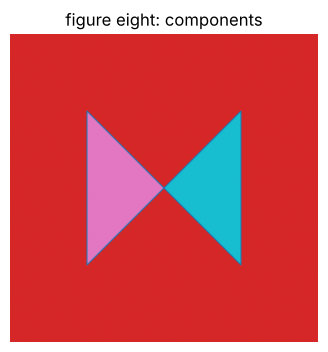

In [5]:
from scipy import ndimage
def seg_dist(X, Y, a, b):
    ax, ay = a; bx, by = b; dx, dy = bx - ax, by - ay
    t = np.clip(((X - ax) * dx + (Y - ay) * dy) / (dx*dx + dy*dy), 0, 1)
    return np.hypot(X - ax - t*dx, Y - ay - t*dy)
def components(P, N=600):
    xs = np.array([p[0] for p in P], float); ys = np.array([p[1] for p in P], float)
    lo, hi = min(xs.min(), ys.min()) - 1, max(xs.max(), ys.max()) + 1
    g = np.linspace(lo, hi, N); X, Y = np.meshgrid(g, g); h = g[1] - g[0]
    D = np.min([seg_dist(X, Y, P[i], P[(i+1) % len(P)]) for i in range(len(P))], axis=0)
    lab, k = ndimage.label(D > h)
    return k, lab
def random_fat(n):
    # star-shaped with equally spaced angles and radii in [1, 2]: no narrow passages
    th = 2*np.pi*(np.arange(n) + rng.uniform(-0.2, 0.2, n))/n; r = rng.uniform(1.0, 2.0, n)
    return [(float(r[i]*np.cos(th[i])), float(r[i]*np.sin(th[i]))) for i in range(n)]
counts = [components(random_fat(15))[0] for _ in range(20)]
print('components for 20 random simple polygons:', counts)
k, lab = components(eight); print('figure eight:', k)
plt.figure(figsize=(4, 4)); plt.imshow(lab, origin='lower', cmap='tab10'); plt.axis('off'); plt.title('figure eight: components'); plt.show()

Two components every time, and three for the figure eight. We used polygons without narrow spikes on purpose: with the spiky polygons of P10.3 a grid of this size pinches thin spikes shut and reports spurious components (try it). A grid computation proves nothing, but it is exactly the kind of check that catches a wrong statement before one tries to prove it.